# SPPU Machine Learning Practical Examination – Question Bank and Solutions

**T. E. Artificial Intelligence & Data Science**  
**Maximum Marks: 25 per question**

This notebook contains 10 practical examination questions. Question 10 has two alternatives (A/B), covering the remaining two experiments: Ensemble Learning and Q-Learning. Thus, all 11 syllabus experiments are represented.

## General instructions
1. Use Python 3 with Jupyter Notebook or Google Colab.
2. Import the required libraries and execute the program.
3. Display suitable outputs, graphs and evaluation metrics.
4. Write a brief conclusion based on the observed results.
5. Install required libraries, if necessary: `pip install numpy pandas matplotlib scikit-learn`.
6. The datasets used below are included in scikit-learn and are accessible through its dataset loaders; no manual download is required.

## Suggested assessment pattern
For most questions: Dataset/preparation – 5; implementation – 10; output/metrics – 5; interpretation – 5. The detailed distribution is given with each question.


## Question 1: Feature Engineering and Data Preprocessing

**Question (25 Marks):** Using a suitable open-access dataset containing numerical and categorical attributes, perform data preprocessing by handling missing values, encoding categorical variables, and scaling numerical features. Prepare a clean, model-ready dataset and demonstrate its suitability for machine learning.

**Dataset:** UCI Wine dataset (loaded through scikit-learn; categorical class labels are derived from the target).

**Tasks:**
1. Load or create a dataset with numerical and categorical columns.
2. Identify and handle missing values using suitable imputation methods.
3. Encode categorical variables using One-Hot or Ordinal Encoding.
4. Scale numerical attributes using StandardScaler or MinMaxScaler.
5. Display the transformed dataset and verify that no missing values remain.

**Suggested marking scheme:** 5: dataset and inspection; 5: missing-value treatment; 5: encoding; 5: scaling; 5: verification and interpretation.

### Python program

In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["class_name"] = df["target"].map(dict(enumerate(wine.target_names))).astype("object")
df = df.drop(columns=["target"])

# Introduce a small number of missing values for demonstrating imputation
df.loc[::20, "alcohol"] = np.nan
df.loc[::25, "class_name"] = np.nan

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore",
                                                sparse_output=False))]), categorical_cols)
])

X_ready = preprocessor.fit_transform(df)
print("Original shape:", df.shape)
print("Transformed shape:", X_ready.shape)
print("Missing values before:", int(df.isna().sum().sum()))
print("Missing values after preprocessing:", int(np.isnan(X_ready).sum()))
print("Model-ready dataset created successfully.")

Original shape: (178, 14)
Transformed shape: (178, 16)
Missing values before: 17
Missing values after preprocessing: 0
Model-ready dataset created successfully.


## Question 2: Dimensionality Reduction using PCA and LDA

**Question (25 Marks):** Apply Principal Component Analysis (PCA) and Linear Discriminant Analysis (LDA) to the high-dimensional Wine dataset. Compare the reduced feature spaces and evaluate their influence on classification accuracy and execution time.

**Dataset:** UCI Wine dataset (13 numerical features and 3 classes; scikit-learn).

**Tasks:**
1. Standardize the input features.
2. Apply PCA and retain components explaining at least 90% variance (or report the variance explained).
3. Apply LDA using the class labels.
4. Train the same classifier on original, PCA-reduced and LDA-reduced data.
5. Compare accuracy, number of features and execution time.

**Suggested marking scheme:** 5: loading and scaling; 5: PCA; 5: LDA; 5: model comparison; 5: conclusion.

### Python program

In [2]:
import time
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X, y = load_wine(return_X_y=True)
X = StandardScaler().fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

pca = PCA(n_components=0.90)
lda = LinearDiscriminantAnalysis(n_components=2)
Xtr_pca = pca.fit_transform(X_train)
Xte_pca = pca.transform(X_test)
Xtr_lda = lda.fit_transform(X_train, y_train)
Xte_lda = lda.transform(X_test)

results = []
for name, a, b in [
    ("Original", X_train, X_test),
    ("PCA", Xtr_pca, Xte_pca),
    ("LDA", Xtr_lda, Xte_lda)]:
    start = time.perf_counter()
    model = LogisticRegression(max_iter=3000)
    model.fit(a, y_train)
    elapsed = time.perf_counter() - start
    pred = model.predict(b)
    results.append([name, a.shape[1], accuracy_score(y_test, pred), elapsed])

print("PCA components:", pca.n_components_)
print("PCA explained variance:", round(pca.explained_variance_ratio_.sum(), 4))
print(pd.DataFrame(results, columns=["Method", "Features", "Accuracy", "Fit time (s)"]))

PCA components: 8
PCA explained variance: 0.9236
     Method  Features  Accuracy  Fit time (s)
0  Original        13  0.977778      0.021019
1       PCA         8  0.977778      0.015908
2       LDA         2  0.977778      0.022068


## Question 3: Multiple Linear Regression

**Question (25 Marks):** Develop a Multiple Linear Regression model using a real-world open-access dataset to predict a continuous target variable. Evaluate the model using MSE, RMSE and R-squared.

**Dataset:** Diabetes dataset from scikit-learn (regression benchmark).

**Tasks:**
1. Load the Diabetes dataset.
2. Separate independent variables and the target variable.
3. Split the dataset into training and testing sets.
4. Train a Multiple Linear Regression model.
5. Predict test values and calculate MSE, RMSE and R-squared.

**Suggested marking scheme:** 5: dataset and preparation; 5: train-test split; 5: model training; 5: evaluation metrics; 5: interpretation.

### Python program

In [3]:
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

mse = mean_squared_error(y_test, pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, pred)

print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)
print(f"MSE: {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2 Score: {r2:.3f}")

Intercept: 151.34560453985995
Coefficients: [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
MSE: 2900.194
RMSE: 53.853
R2 Score: 0.453


## Question 4: Polynomial Regression and Bias–Variance Trade-off

**Question (25 Marks):** Implement Polynomial Regression on a suitable dataset using different polynomial degrees. Analyze how model complexity affects training and testing errors and explain the bias–variance trade-off.

**Dataset:** Diabetes dataset from scikit-learn (one selected feature and continuous target).

**Tasks:**
1. Use the Diabetes dataset and select one numerical feature for prediction.
2. Fit polynomial regression models of degrees 1, 2, 3, 5 and 8.
3. Calculate training and testing MSE for each degree.
4. Plot actual observations and fitted curves.
5. Identify underfitting or overfitting based on the error values.

**Suggested marking scheme:** 5: data preparation; 5: polynomial feature generation; 5: model fitting; 5: error comparison; 5: plot and interpretation.

### Python program

Degree 1: train MSE=3930.99, test MSE=3775.62
Degree 2: train MSE=3924.39, test MSE=3803.66
Degree 3: train MSE=3924.33, test MSE=3798.12
Degree 5: train MSE=3904.22, test MSE=3785.76
Degree 8: train MSE=3799.50, test MSE=7282.92


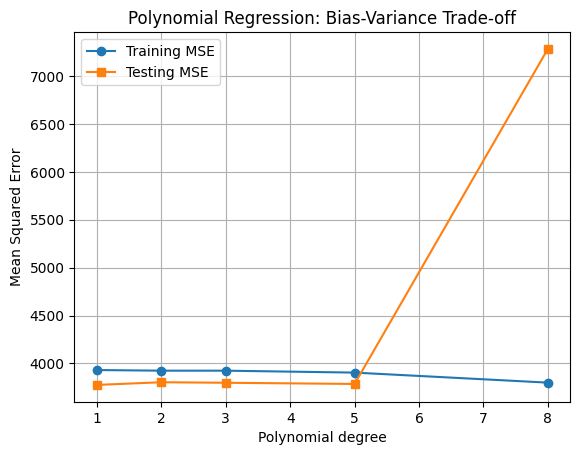

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

data = load_diabetes()
# Use one feature to make the fitted curves easy to visualize
X = data.data[:, [2]]
y = data.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42)

degrees = [1, 2, 3, 5, 8]
train_errors, test_errors = [], []

for degree in degrees:
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    Xtr = poly.fit_transform(X_train)
    Xte = poly.transform(X_test)
    model = LinearRegression()
    model.fit(Xtr, y_train)
    train_errors.append(mean_squared_error(y_train, model.predict(Xtr)))
    test_errors.append(mean_squared_error(y_test, model.predict(Xte)))
    print(f"Degree {degree}: train MSE={train_errors[-1]:.2f}, "
          f"test MSE={test_errors[-1]:.2f}")

plt.plot(degrees, train_errors, marker="o", label="Training MSE")
plt.plot(degrees, test_errors, marker="s", label="Testing MSE")
plt.xlabel("Polynomial degree")
plt.ylabel("Mean Squared Error")
plt.title("Polynomial Regression: Bias-Variance Trade-off")
plt.legend()
plt.grid(True)
plt.show()

## Question 5: Regularized Regression using Ridge and Lasso

**Question (25 Marks):** Apply Ridge and Lasso regression to a multivariate dataset. Compare their predictive performance and examine the effect of regularization on model coefficients and overfitting.

**Dataset:** Diabetes dataset from scikit-learn.

**Tasks:**
1. Load and standardize the Diabetes dataset.
2. Split the data into training and testing sets.
3. Train Linear Regression, Ridge and Lasso models.
4. Compare MSE and R-squared values.
5. Display and compare model coefficients; comment on coefficient shrinkage and feature selection.

**Suggested marking scheme:** 5: data preparation; 5: baseline model; 5: Ridge and Lasso; 5: metric comparison; 5: coefficient analysis.

### Python program

In [5]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Lasso": make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=10000))
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append([name, mean_squared_error(y_test, pred),
                 r2_score(y_test, pred)])

print(pd.DataFrame(rows, columns=["Model", "MSE", "R2"]))

# Compare coefficients on the standardized feature scale
for name in ["Linear Regression", "Ridge", "Lasso"]:
    estimator = models[name].named_steps[list(models[name].named_steps)[-1]]
    print(name, np.round(estimator.coef_, 3) if hasattr(estimator, "coef_") else "")

               Model          MSE        R2
0  Linear Regression  2900.193628  0.452603
1              Ridge  2892.014566  0.454147
2              Lasso  2884.624289  0.455541
Linear Regression [  1.754 -11.512  25.607  16.829 -44.449  24.641   7.677  13.139  35.161
   2.351]
Ridge [  1.807 -11.448  25.733  16.734 -34.672  17.053   3.37   11.764  31.378
   2.458]
Lasso [  1.73  -11.316  25.825  16.644 -29.358  13.276   0.548  10.236  29.633
   2.393]


## Question 6: Binary Classification using Logistic Regression

**Question (25 Marks):** Build a Logistic Regression classifier on a suitable open-access dataset for binary classification. Evaluate its performance using a confusion matrix, precision, recall and F1-score.

**Dataset:** Breast Cancer Wisconsin dataset from scikit-learn (binary classification).

**Tasks:**
1. Load the Breast Cancer Wisconsin dataset.
2. Split the dataset using stratified sampling.
3. Standardize the features.
4. Train a Logistic Regression classifier.
5. Display the confusion matrix, precision, recall, F1-score and accuracy.

**Suggested marking scheme:** 5: dataset and split; 5: preprocessing; 5: model training; 5: confusion matrix; 5: metrics and interpretation.

### Python program

In [6]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, precision_score,
                             recall_score, f1_score)

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=5000))
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("Confusion Matrix:\n", confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, target_names=load_breast_cancer().target_names))
print("Accuracy :", accuracy_score(y_test, pred))
print("Precision:", precision_score(y_test, pred))
print("Recall   :", recall_score(y_test, pred))
print("F1-score :", f1_score(y_test, pred))

Confusion Matrix:
 [[41  1]
 [ 1 71]]
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Accuracy : 0.9824561403508771
Precision: 0.9861111111111112
Recall   : 0.9861111111111112
F1-score : 0.9861111111111112


## Question 7: Support Vector Machine with Linear and Nonlinear Kernels

**Question (25 Marks):** Implement Support Vector Machine classification using linear and nonlinear kernels on a suitable dataset. Compare their classification performance using appropriate evaluation metrics.

**Dataset:** Breast Cancer Wisconsin dataset from scikit-learn.

**Tasks:**
1. Load the Breast Cancer Wisconsin dataset.
2. Split and standardize the data.
3. Train SVM classifiers using linear, RBF and polynomial kernels.
4. Calculate accuracy, precision, recall and F1-score.
5. Compare the kernels and identify the best-performing model.

**Suggested marking scheme:** 5: data preparation; 5: scaling; 5: SVM implementation; 5: metric calculation; 5: comparison.

### Python program

In [7]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

results = []
for kernel in ["linear", "rbf", "poly"]:
    model = make_pipeline(StandardScaler(),
                          SVC(kernel=kernel, C=1.0, gamma="scale"))
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results.append([kernel, accuracy_score(y_test, pred),
                    precision_score(y_test, pred),
                    recall_score(y_test, pred),
                    f1_score(y_test, pred)])

print(pd.DataFrame(results, columns=[
    "Kernel", "Accuracy", "Precision", "Recall", "F1-score"]))

   Kernel  Accuracy  Precision    Recall  F1-score
0  linear  0.973684   0.985915  0.972222  0.979021
1     rbf  0.982456   0.986111  0.986111  0.986111
2    poly  0.912281   0.878049  1.000000  0.935065


## Question 8: K-Means Clustering and Optimal Number of Clusters

**Question (25 Marks):** Apply K-Means clustering to an open-access dataset and determine the optimal number of clusters using the Elbow method and/or Silhouette score. Visualize and interpret the resulting clusters.

**Dataset:** UCI Wine dataset from scikit-learn.

**Tasks:**
1. Load the Wine dataset and standardize its features.
2. Calculate inertia for different values of K.
3. Plot the Elbow curve.
4. Calculate Silhouette scores and select a suitable K.
5. Fit K-Means and visualize clusters using a two-dimensional PCA projection.

**Suggested marking scheme:** 5: data preparation; 5: Elbow method; 5: Silhouette analysis; 5: clustering; 5: visualization and interpretation.

### Python program

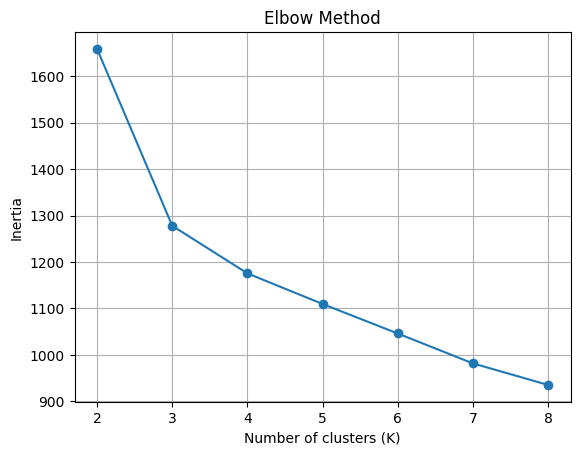

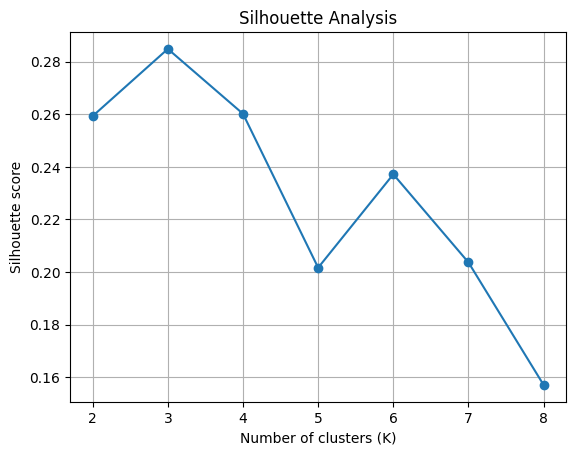

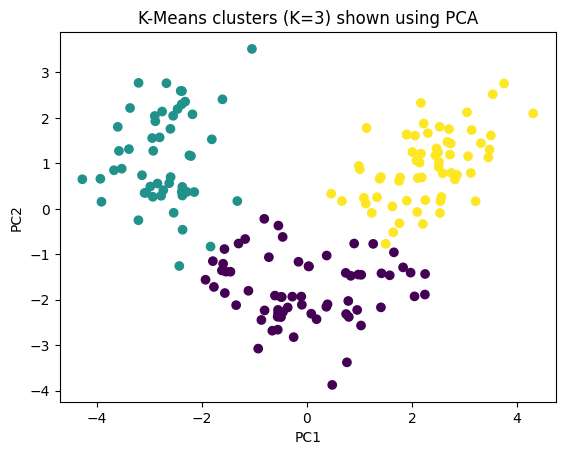

Selected K: 3
Silhouette score: 0.2848589191898987


In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

X, y = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

inertias, silhouettes = [], []
k_values = range(2, 9)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

plt.plot(list(k_values), silhouettes, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Analysis")
plt.grid(True)
plt.show()

best_k = list(k_values)[int(silhouettes.index(max(silhouettes)))]
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
labels = kmeans.fit_predict(X_scaled)
X_2d = PCA(n_components=2).fit_transform(X_scaled)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.title(f"K-Means clusters (K={best_k}) shown using PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()
print("Selected K:", best_k)
print("Silhouette score:", max(silhouettes))

## Question 9: Density-Based Clustering using DBSCAN

**Question (25 Marks):** Apply DBSCAN to a suitable open-access dataset to identify dense clusters and noise points. Study the effect of the eps and min_samples parameters on clustering results.

**Dataset:** UCI Wine dataset from scikit-learn.

**Tasks:**
1. Load and standardize the Wine dataset.
2. Apply DBSCAN with suitable eps and min_samples values.
3. Identify cluster labels and noise points (label -1).
4. Report the number of clusters and noise samples.
5. Visualize the clustering result using PCA projection and discuss parameter effects.

**Suggested marking scheme:** 5: data preparation; 5: DBSCAN implementation; 5: cluster/noise identification; 5: visualization; 5: interpretation.

### Python program

Number of clusters: 1
Number of noise points: 24
Cluster labels: [-1  0]


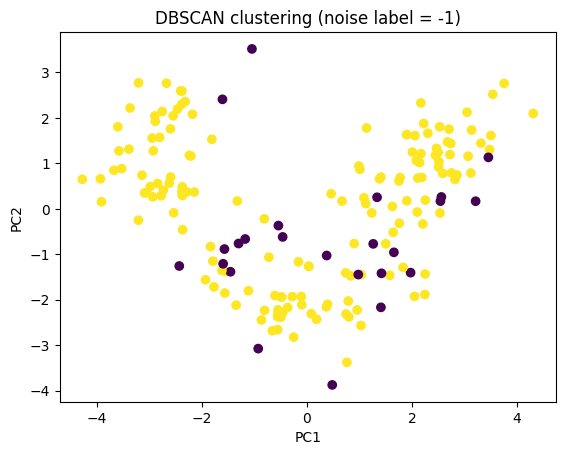

eps=1.5: clusters=0, noise=178
eps=2.0: clusters=5, noise=85
eps=2.5: clusters=1, noise=24
eps=3.0: clusters=1, noise=11


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN

X, y = load_wine(return_X_y=True)
X_scaled = StandardScaler().fit_transform(X)

# eps is data-dependent; experiment with nearby values if all points
# become noise or a single cluster is produced.
dbscan = DBSCAN(eps=2.5, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

cluster_labels = set(labels) - {-1}
noise_count = int(np.sum(labels == -1))
print("Number of clusters:", len(cluster_labels))
print("Number of noise points:", noise_count)
print("Cluster labels:", np.unique(labels))

X_2d = PCA(n_components=2).fit_transform(X_scaled)
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels)
plt.title("DBSCAN clustering (noise label = -1)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

# Parameter sensitivity experiment
for eps in [1.5, 2.0, 2.5, 3.0]:
    lab = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
    print(f"eps={eps}: clusters={len(set(lab)-{-1})}, "
          f"noise={np.sum(lab == -1)}")

## Question 10: Ensemble Learning OR Reinforcement Learning

**Question (25 Marks):** Option A – Ensemble Learning: Compare a baseline Decision Tree classifier with Random Forest and a Boosting classifier on a suitable open-access dataset. Evaluate and compare their performance.

OR

Option B – Reinforcement Learning: Implement Q-Learning for a 4 × 4 Grid World problem. Demonstrate exploration and exploitation using an epsilon-greedy strategy and evaluate the learned policy.

**Dataset:** Option A: Breast Cancer Wisconsin dataset. Option B: self-defined 4 × 4 Grid World.

**Tasks:**
1. Option A: Load Breast Cancer dataset, split data, train Decision Tree, Random Forest and AdaBoost models, and compare accuracy, precision, recall and F1-score.
2. Option B: Define a 4 × 4 Grid World with start and goal states, actions, rewards and terminal condition.
3. Option B: Implement Q-table updates using learning rate, discount factor and epsilon-greedy action selection.
4. Option B: Train over multiple episodes and display the learned policy and success rate.

**Suggested marking scheme:** 25 marks: Option A – 5 data preparation, 10 model implementation, 5 evaluation, 5 comparison. Option B – 5 environment/rewards, 10 Q-Learning implementation, 5 training/policy, 5 interpretation.

### Python program

In [10]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

models = {
    "Decision Tree (baseline)": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=42)
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append([name, accuracy_score(y_test, pred),
                 precision_score(y_test, pred),
                 recall_score(y_test, pred),
                 f1_score(y_test, pred)])

print(pd.DataFrame(rows, columns=[
    "Model", "Accuracy", "Precision", "Recall", "F1-score"]))

C:\Users\Chandrashekhar\anaconda3\envs\venv\lib\site-packages\sklearn\ensemble\_weight_boosting.py:527: FutureWarning: The SAMME.R algorithm (the default) is deprecated and will be removed in 1.6. Use the SAMME algorithm to circumvent this warning.
  warnings.warn(


                      Model  Accuracy  Precision    Recall  F1-score
0  Decision Tree (baseline)  0.912281   0.955882  0.902778  0.928571
1             Random Forest  0.956140   0.958904  0.972222  0.965517
2                  AdaBoost  0.956140   0.946667  0.986111  0.965986
